In [121]:
# These are the libraries you may use for this assignment.
# If you would like to use any other libraries, email james@uwaterloo.ca for permission first.
# Generative AI tools (including coding assistants) are not permitted for this assignment.

from IPython.display import display, Math, Latex

import pandas as pd
import numpy as np
import numpy_financial as npf
import yfinance as yf
import matplotlib.pyplot as plt
import random
from datetime import datetime

## CFM 101 — Group Assignment 2026
### Robo-Advising Challenge: Two Clients, Two Strategies

**Team Number:** XX  
**Team Member Names (three or four):**  Yogi, Olyvia, Lyn, Stepan

Enter the names of all participating members below (one name per line):

Yogi Shah

Olyvia Song

Lyn Khine

Stepan Pokutny

**Submission:** Friday, November 27, 2026, at 9:00 AM (Eastern), via Dropbox.  
**Submit this completed Jupyter notebook only.**

Your team must construct **both** portfolios from the supplied `Tickers.csv` file:

- **Client A — Growth:** $\$1,000,000$ CAD; seek the highest expected return.
- **Client B — Low Risk:** $\$750,000$ CAD; seek the lowest portfolio volatility.

Both clients require 10–20 eligible stocks, at most 15% in any stock and at most 40% in any sector. Read the full assignment handout for all eligibility, fee, currency, and competition rules. Do not hardcode the selected stocks. Check that tickers are valid. The supplied ticker universe will permit feasible portfolios.

**No generative AI may be used in preparing this assignment.**

## Data preparation and shared functions

Read `Tickers.csv`, check ticker eligibility, retrieve the data needed for your strategies, and create any functions you will reuse for both clients. Use closing prices from **November 27, 2026** for the purchase calculations. All portfolio values and weights must be calculated in CAD, with purchase fees paid from the client budget.

In [122]:
GROUP_NUMBER = "9"
TICKER_FILE = "Tickers_Example.csv" #the TAs file: Tickers_Example.csv only for practice

#For practice runs set PURCHASE_DATE to the latest trading day that already has data
#set it back to "2026-11-27" for the final submission.
PURCHASE_DATE = "2026-11-25"# buy at this day's close
HIST_START, HIST_END = "2025-11-27", PURCHASE_DATE # history window for stats and equal-weight comparison
VOLUME_START = "2025-10-01"
VOLUME_END = "2026-10-01" #yfinance's end date is exclusive, so this covers through Sep 30, 2026  
END_DATE = "2026-12-01" 

MIN_AVG_VOLUME = 5_000
MIN_TRADING_DAYS = 18# months with fewer trading days are ignored in the volume average

FEE_CAP_USD = 2.15
FEE_PER_SHARE_USD = 0.001
TRADING_DAYS = 252 # the total number of trading days in a year

CLIENTS = {
    "A": dict(name="Growth",   budget=1_000_000, n_min=10, n_max=20, max_weight=0.15, max_sector=0.40),
    "B": dict(name="Low Risk", budget=750_000,   n_min=10, n_max=20, max_weight=0.15, max_sector=0.40),
}


#Read Tickers.csv and drop duplicates, return a list of tickers
def load_tickers(path=TICKER_FILE):
    tickers = pd.read_csv(path, header=None, names=['Ticker'])
    return tickers['Ticker'].dropna().astype(str).str.strip().str.upper().drop_duplicates().tolist()

#Filter stocks based on assignment eligibility (first initial filter) and return a list of filtered stocks and a dictionary with sector, currency, market
def filter_ticks(tickers, min_volume=MIN_AVG_VOLUME, min_days_per_month=MIN_TRADING_DAYS):
    filtered = []
    records = {}

    for i in tickers:
        try:
            ticker = yf.Ticker(i)

            history = ticker.history(start=VOLUME_START, end=VOLUME_END)

            if history.empty:  # ticker is invalid or has no data for the specified date range
                continue

            vol = history['Volume']
            month = history.index.strftime('%Y-%m')  # used to group by month
            avg_vol = vol[vol.groupby(month).transform('count') >= min_days_per_month]  # keep only months with at least min_days_per_month trading days

            # an empty avg_vol (no month with enough trading days) must be rejected
            if avg_vol.empty or avg_vol.mean() < min_volume:
                continue

            info = ticker.info  # run after the volume check to save runtime
            market = info.get('market')
            if ((market == 'us_market' or market == 'ca_market') #US or Canadian listing, quoted in USD or CAD, company stock 
                    and (info.get('currency') == 'USD' or info.get('currency') == 'CAD')
                    and (info.get('quoteType') == 'EQUITY')):
                filtered.append(i)
                records[i] = {"currency": info.get('currency'),
                              "sector": info.get('sector') or "Unknown",   # needed for the sector cap
                              "market": market,
                              "beta": info.get('beta')}
        except Exception:
            continue  # skip the invalid tickers or download errors

    return filtered, pd.DataFrame.from_dict(records, orient="index", columns=["currency", "sector", "market", "beta"])

#returns dictionary with filtered info, prices_local, and current exchange rate
def load_market_data(tickers, info, start=HIST_START, end=PURCHASE_DATE):
    end_plus_one = (pd.Timestamp(end) + pd.Timedelta(days=1)).strftime('%Y-%m-%d')  # yfinance's end date is exclusive

    # one download for all the stocks plus the exchange rate
    # auto_adjust=False gives plain closing prices 
    close = yf.download(list(tickers) + ['USDCAD=X'], start=start, end=end_plus_one,
                        auto_adjust=False, progress=False)['Close']

    fx = close['USDCAD=X'].ffill() #exchange rate by date
    prices_local = close.drop(columns='USDCAD=X')
    prices_local = prices_local.dropna(axis=1, how='all')#drop tickers that failed to download
    prices_local = prices_local.loc[:, prices_local.loc[end].notna()] #drop tickers with no price on the purchase date
    prices_local = prices_local.ffill()#fill holiday gaps with the previous close

    return {"info": info.loc[prices_local.columns], "prices_local": prices_local, "fx": fx} #returns a dictionary that holds three items, "info" dataframe, "prices_local" dataframe, and "fx" series

#return current local prices dataframe converted to cad from usd using current exchange rate from above function
def to_cad_prices(prices_local, info, fx):
    prices_cad = prices_local.copy()
    for ticker in prices_cad.columns:
        if info.loc[ticker, "currency"] == "USD":
            prices_cad[ticker] = prices_local[ticker] * fx   # price in USD x CAD per 1 USD
    return prices_cad

#ticker_csv = load_tickers(path=TICKER_FILE)
#filtered_ticks, info_df = filter_ticks(ticker_csv)
#print(filtered_ticks, info_df)
#market_data_usd_cad = load_market_data(filtered_ticks, info_df)
#print(market_data_usd_cad)
#market_data_cad = to_cad_prices(market_data_usd_cad['prices_local'], market_data_usd_cad['info'], market_data_usd_cad['fx'])
#print(market_data_cad)

#computes daily returns for all tickers in prices dataframe
def compute_returns(prices_cad):
    return prices_cad.pct_change().dropna(how="all") 

#calculate the total fee that will need to be paid to subtract if from the budget
def transaction_fee_cad(shares, usdcad):
    #Each stock's fee is either US$2.15 and US$0.001 per share, converted to CAD
    total_fee = 0
    for number_of_shares in shares:
        fee_usd = min(FEE_CAP_USD, FEE_PER_SHARE_USD * number_of_shares)
        total_fee = total_fee + fee_usd * usdcad
    return total_fee

#makes sure that purchases + fees = budget and repeats the calculation for the fees multiple times, returns the total fees and series of shares bought for each stock
def allocate_shares(weights, price_cad, usdcad, budget):
    fees = 0
    for _ in range(10):
        shares = weights * (budget - fees) / price_cad #spend what's left after fees
        fees = transaction_fee_cad(shares, usdcad) #recalculate fees for those shares
    return shares, fees

#filtered, info = filter_ticks(load_tickers())
#print(filtered)
#print(info)


In [123]:
import scipy
from scipy.optimize import minimize, LinearConstraint

#get beta from yahoo finance using info dictionary so we don't have to call yfinance api again
def beta(ticker):
    return info.loc[ticker, 'beta']

#Calculate volatility using standard deviation of daily returns
def volatility(ticker, returns):
    return returns[ticker].std() 

#average daily returns
def expected_returns(ticker, returns):
    return returns[ticker].mean() 

#it is small when the stocks are calm and don't move together, so minimize looks for the weights that make it smallest
def portfolio_variance(weights, returns):
    portfolio_returns = (returns * weights).sum(axis=1)
    return portfolio_returns.var()

#Pick 10 stocks for Client A (highest expected return) by scoring based on ranking betas and expected return, returns list of tickers
def select_stocks_A(returns, info, n):
    #collect each eligible stock's ticker, expected return and beta
    tickers = []
    expected = []
    betas = []

    for ticker in returns.columns: #for stocks with valid returns
        tickers.append(ticker)
        expected.append(expected_returns(ticker, returns))
        betas.append(beta(ticker))

    #put the lists into one table with each stock's sector
    stats = pd.DataFrame(index=tickers)
    stats["sector"] = info.loc[tickers, "sector"]
    stats["expected_return"] = expected
    stats["beta"] = betas
    stats = stats.dropna() #drop invalid values

    #rank both measures and add the ranks into a score, lower score is a better stock
    stats["rank_return"] = stats["expected_return"].rank(ascending=False)
    stats["rank_beta"] = stats["beta"].rank(ascending=False)
    stats["score"] = stats["rank_return"] + stats["rank_beta"]
    #print(stats)
    stats = stats.sort_values(["score", "expected_return"], ascending=[True, False])
    stats = stats[stats["expected_return"] > 0] #filter all negative returns, as a final check

    #go down the ranking and pick stocks, taking at most 40% * n from the same sector
    max_per_sector = int(CLIENTS["A"]["max_sector"] * n) #0.4 * 10 = 4 stocks
    selected = []
    for ticker in stats.index: #each ticker ranked by score, lowest score ranked first
        if len(selected) == n:
            break
        sector = stats.loc[ticker, "sector"]
        count = 0 #count resets for each stock
        for chosen in selected:
            if stats.loc[chosen, "sector"] == sector: #if the sector is the same as the current iteration
                count = count + 1 #how many stocks from the same sector are already selected (and ranked higher)
        if count < max_per_sector:
            selected.append(ticker) #still space

    return selected

def weight_stocks_A(selected, returns, info):
    """Raw weights for Client A (before caps). Output: Series indexed by ticker, summing to 1"""
    #limits: 15% per stock and 40% per sector
    max_weight = CLIENTS["A"]["max_weight"]
    max_sector = CLIENTS["A"]["max_sector"]

    n = len(selected)
    expected = list(returns[selected].mean())

    #for each sector make a row of ones (if stock is in this sector) and zeros (if it isn't)
    sector_rows = []
    for sector in info.loc[selected, "sector"].unique():
        row = []
        for ticker in selected:
            if info.loc[ticker, "sector"] == sector:
                row.append(1)
            else:
                row.append(0)
        sector_rows.append(row)

    
    start = [1 / n] * n
    bounds = [(0.01, max_weight)] * n
    constraints = [LinearConstraint([1] * n, 1, 1), LinearConstraint(sector_rows, 0, max_sector)]

    #try different weights within these rules and keep the ones with the highest portfolio expected return
    result = minimize(negative_portfolio_return, start, args=(expected,), method="SLSQP", bounds=bounds, constraints=constraints, tol=1e-12)
    
    return pd.Series(result.x, index=selected)

#minimize can only make things smaller, so making the negative return as small as possible makes the real return as large as possible
def negative_portfolio_return(weights, expected):
    total = 0
    for i in range(len(weights)):
        total = total + weights[i] * expected[i]
    return -total

#pick 20 stocks for Client B (low volatility), returns a list of 20 tickers for weighting
def select_stocks_B(returns, info, n):
    #collect each eligible stock's ticker, standard deviation and beta
    tickers = []
    std = []
    betas = []

    for ticker in returns.columns:
        tickers.append(ticker)
        std.append(volatility(ticker, returns))
        betas.append(beta(ticker))

    #put the lists into one table with each stock's sector
    stats = pd.DataFrame(index=tickers)
    stats["sector"] = info.loc[tickers, "sector"]
    stats["standard_deviation"] = std
    stats["beta"] = betas
    stats = stats.dropna()

    #rank both measures and add the ranks into a score, lower score is a better stock
    stats["rank_volatility"] = stats["standard_deviation"].rank(ascending=True) #lowest volatility is first
    stats["rank_beta"] = stats["beta"].rank(ascending=True) #lowest beta is first
    stats["score"] = stats["rank_volatility"] + stats["rank_beta"]
    stats = stats.sort_values(["score", "standard_deviation"], ascending=[True, True]) 
    stats = stats[stats["standard_deviation"] > 0] #volatility is greater than 0, stock is actively traded

    #go down the ranking and pick stocks, taking at most 40% * n from the same sector
    max_per_sector = int(CLIENTS["B"]["max_sector"] * n) #0.4 * 20
    selected = []
    for ticker in stats.index:
        if len(selected) == n: #filled all 20 stock slots
            break
        sector = stats.loc[ticker, "sector"]
        count = 0 #count resets for each different sector
        for chosen in selected:
            if stats.loc[chosen, "sector"] == sector: #how many stocks from the same sector are already selected (and ranked higher)
                count = count + 1
        if count < max_per_sector: #have not reached the max of 8 stocks for each stock
            selected.append(ticker)

    return selected


def weight_stocks_B(selected, returns, info):
    """Raw weights for Client B (before caps). Output: Series indexed by ticker, summing to 1"""
    #limits: 15% per stock and 40% per sector
    max_weight = CLIENTS["B"]["max_weight"]
    max_sector = CLIENTS["B"]["max_sector"]
    n = len(selected)

    #daily returns of the picked stocks, only the days on which all of them have data
    stock_returns = returns[selected].dropna()

    #for each sector make a row of ones (if stock is in this sector) and zeros (if it isn't)
    sector_rows = []
    for sector in info.loc[selected, "sector"].unique(): #extracts all distinct values from a dataframe by removing duplicates
        row = []
        for ticker in selected:
            if info.loc[ticker, "sector"] == sector:
                row.append(1)
            else:
                row.append(0)
        sector_rows.append(row)

    start = [1 / n] * n
    bounds = [(0.01, max_weight)] * n
    constraints = [LinearConstraint([1] * n, 1, 1), LinearConstraint(sector_rows, 0, max_sector)]

    #try different weights within these rules and keep the ones with the lowest portfolio variance
    result = minimize(portfolio_variance, start, args=(stock_returns,), method="SLSQP", bounds=bounds, constraints=constraints, tol=1e-12)
    return pd.Series(result.x, index=selected)


In [124]:
#builds the final portfolio dataframe the same way for both clients, also calls allocate_shares to buy them
def finish_portfolio(client, selected, weights, data, returns, prices_cad, usdcad):
    client_info = CLIENTS[client]
    info = data["info"]


    price_cad_buy = prices_cad.loc[PURCHASE_DATE] #
    prices_local_buy = data["prices_local"].loc[PURCHASE_DATE]
    shares, fees = allocate_shares(weights, price_cad_buy[selected], usdcad, client_info["budget"]) #get series for shares and fees for each stock

    #build final portfolio dataframe column by column
    portfolio = pd.DataFrame(index=shares.index)
    portfolio["Price"] = prices_local_buy[shares.index]
    portfolio["Currency"] = info.loc[shares.index, "currency"]
    portfolio["Shares"] = shares
    portfolio["Value"] = shares * price_cad_buy[shares.index]
    portfolio["Weight"] = portfolio["Value"] / portfolio["Value"].sum() #fees are calculated from the dataframe, but they are the same as raw_weights_a and raw_weights_b (just with fees taken into account)

    portfolio.index.name = "Ticker"
    portfolio = portfolio.reset_index() # turn the ticker index into a column
    portfolio.index = range(1, len(portfolio) + 1)  #starts index at 1 instead of 0

    return portfolio, weights, fees


# load and prepare the data
tickers = load_tickers(TICKER_FILE)
eligible, info = filter_ticks(tickers)
data = load_market_data(eligible, info)
prices_cad = to_cad_prices(data["prices_local"], info, data["fx"])

#return {"info": info.loc[prices_local.columns], "prices_local": prices_local, "fx": fx} (for reference)

#filters for basic requirements --> filters out penny stocks, unkown sector
def second_filter(eligible, data, info):
    kept = []
    if (len(eligible) <= 20): #skip second filter if too many stocks have already been filtered out
        return eligible
    
    for ticker in eligible:
        if data['prices_local'].loc[PURCHASE_DATE, ticker] < 5: #remove penny stocks, unavoidable plummets/spikes, low liquidity (current price is less than 5 dollars)
            continue
        if info.loc[ticker, 'sector'] == 'Unknown': #remove stocks with unknown sector
            continue
        kept.append(ticker)
    return kept

info = data["info"]
eligible = list(info.index)  # after dropping tickers with no purchase-date price
eligible = second_filter(eligible, data, info)

returns = compute_returns(prices_cad[eligible])
usdcad = data["fx"].loc[PURCHASE_DATE]

$AGN: possibly delisted; no timezone found
$BK: possibly delisted; no price data found  (1d 2025-10-01 -> 2026-10-01)
$CELG: possibly delisted; no timezone found
$MON: possibly delisted; no timezone found
$RTN: possibly delisted; no timezone found


## Client A — Growth

Construct a portfolio intended to achieve the **highest expected return**. Use your selected stocks and portfolio weights to create a DataFrame named `Portfolio_Final_A` with index **1 through n** and columns (in this order): `Ticker`, `Price`, `Currency`, `Shares`, `Value`, `Weight`. `Price` is in the stock’s quoted currency, `Value` is in CAD, and `Weight` is a fraction summing to 1.

In [125]:
N_STOCKS_A = 10 #optimize just for highest expected return stocks, take the minimum number of stocks

selected_A = select_stocks_A(returns[eligible], info, N_STOCKS_A)
raw_weights_A = weight_stocks_A(selected_A, returns, info)
Portfolio_Final_A, weights_A, fees_A = finish_portfolio("A", selected_A, raw_weights_A, data, returns, prices_cad, usdcad) #create the final portfolio dataframe, and also series for weights and fees


### Client A — Financial justification

**Why does this portfolio make financial sense?** Explain how and why you select and weight stocks.  
Our strategy is aimed at a growth-oriented client who is willing to accept greater risk in exchange for potentially greater returns. Thus, we selected stocks by ranking their historical average daily returns and beta. Stocks with higher expected returns and higher betas received better rankings, as they offer greater growth potential and are more sensitive to market movements. We combined rankings of two variables into a score, selecting the highest-ranked stock, while limiting the number of stocks from each sector to promote diversification. The lower the score, the better, as it indicates the rank is higher.   

After selecting the stocks, we implemented the minimize() function from the SciPy library to optimize portfolio weights. We used a function called negative_expected_return() that calculates the negative of the portfolio’s expected return. By minimizing negative return, the actual expected return is maximized. We imposed constraints of a minimum of 1%, a maximum weight of 15% per stock and 40% for the entire sector to prevent excessive concentration, ensuring all weights add up to 100%. These constraints allow the portfolio to prioritize stocks with stronger expected returns while maintaining diversification. This approach aligns with Client A’s growth objective. 


**What evidence supports your strategy?** Discuss relevant statistics and the equal-weight comparison below.   
Our strategy is supported by historical performance and risk statistics of the selected stocks. For example, the portfolio’s annualized return was 40.78%, indicating that it’s aligned with growth. When comparing the optimized portfolio with the equal-weight comparison portfolio, there were differences in volatility. The optimized portfolio achieved a return of 40.78%, volatility of 20.58%, whereas the equal-weight portfolio achieved a return of 31.89% and volatility of 21.86%. Comparing these variables, it shows that the strategic portfolio has higher expected returns, with a similar amount of volatility.

**What could go wrong?** Identify at least one important limitation or situation in which this strategy may perform poorly.   
One limitation is that the strategy relies on historical returns and beta to estimate future performance. Past performance may not continue to do well in the future, and changes in market conditions could cause the selected stocks to perform differently from what the past trends had displayed. In addition, maximizing expected returns may cause a portfolio to place greater weight on stocks with unusually high returns, which isn’t substantial. Although placing weight limits reduces the concentration risk, the portfolio could still experience significant losses during market downturns. Additionally, since historic returns are used to calculate expected returns, if a stock instead falls and we with our optimization for high beta (assuming positive expected returns), it will cause portfolio value to drop significantly. This is because higher-beta stocks tend to be more sensitive to any market movements. 

## Client B — Low Risk

Construct a portfolio intended to achieve the **lowest risk**, defined as the standard deviation of daily portfolio returns in CAD. Create `Portfolio_Final_B` using the same DataFrame column names, order, and index convention as for Client A.

In [126]:
N_STOCKS_B = 20 #choose the maximum number of stocks for diversification

selected_B = select_stocks_B(returns[eligible], info, N_STOCKS_B)
raw_weights_B = weight_stocks_B(selected_B, returns, info)
Portfolio_Final_B, weights_B, fees_B = finish_portfolio("B", selected_B, raw_weights_B, data, returns, prices_cad, usdcad) #create the final portfolio dataframe, and also series for weights and fees

### Client B — Financial justification

**Why does this portfolio make financial sense?** Explain how and why you select and weight stocks.  
For Client B, we select stocks using two risk-related variables: volatility and beta. We measure how much a stock’s returns fluctuate with volatility, while beta indicates a stock’s sensitivity to overall market movements. Lower volatility means its returns have been more historically stable. Lower beta generally means stocks are less sensitive to market fluctuations. Similar to Client A, we take in both variables and rank stocks in ascending order for both volatility and beta, where a lower rank number represents a lower-risk stock. We then add the two ranks together to create a total score. Stocks with lower total scores are prioritized as they are more stable across both risk measurements, which aligns with Client B’s objective to have low risk. After selecting stocks, we use the same function, minimize(), as Client A for portfolio optimization. Unlike Client A, where the minimize() function takes in negative return, we took portfolio variance to measure the fluctuations in the portfolio’s overall returns. Portfolio variance considers how stocks move relative to one another; therefore, stocks that don’t move closely together can help reduce the overall risk. The minimize function tests all combinations of weights that reduce the overall portfolio risk. The same constraints are placed as in A for the same reason: to prevent oversaturation in a stock or sector. 


**What evidence supports your strategy?** Discuss relevant statistics and the equal-weight comparison below.  
Comparing our optimized portfolio with an equal-weight portfolio consisting of the same selected stocks shows us two variables: annualized returns and volatility. The optimized portfolio achieved a return of 24.76%, volatility of 11.45%, whereas the equal-weight portfolio achieved a return of 20.79% and volatility of 13.4%. The optimized lower volatility indicates our weighting strategy reduced the portfolio’s overall risk relative to the equal-weight portfolio. This comparison helps us evaluate whether our optimization was successfully achieved in Client B’s low-risk objective while considering potential trade-offs in returns. 

**What could go wrong?** Identify at least one important limitation or situation in which this strategy may perform poorly.  
One limitation of using our current financial strategy is its reliance on historical volatility and correlation, which may not accurately reflect future market conditions. Stocks with low volatility in the past may experience higher volatility due to unexpected events in the market, and the relationship between stocks may change over time, reducing the effectiveness of diversification. Furthermore, minimizing portfolio variance doesn’t guarantee the lowest possible losses or eliminate market risk. By prioritizing lower-risk stocks, the strategy may not make the highest returns. One particular situation where our strategy may not be optimal is when a normally stable sector falls. This is because we maximize investment into the most stable sectors, for example capping at 40% in defense, but if there are unpredictable changes in a stable sector, our overall return will suffer greatly.

## Equal-weight comparisons

For **each client**, create an equal-weighted comparison portfolio holding **exactly the same stocks** as that client’s chosen portfolio, with starting weight `1/n` per stock. Over the same clearly identified historical period, calculate **historical return** and **volatility** for the chosen portfolio and its equal-weighted counterpart. Use consistent CAD valuations and weighting assumptions.

Display one concise comparison table per client, and interpret the results in the financial justifications above. No additional graph or out-of-sample test is required.

In [127]:
#Historical yearly return and volatility of a portfolio with the according weighting calculations
def portfolio_stats(weights, returns):
    """Historical yearly return and volatility of a portfolio with fixed weights.
    Output: dict with 'Return' and 'Volatility'"""
    stock_returns = returns.loc[HIST_START:HIST_END, weights.index].dropna()
    portfolio_returns = (stock_returns * weights).sum(axis=1)   # each day: sum of weight x stock return
    return {"Return": portfolio_returns.mean() * 252,
            "Volatility": portfolio_returns.std() * (252 ** 0.5)}

#control variable, seeing how much volatility and return a stock has if its holdings were all weighted equally
def equal_weight_comparison(final_weights, returns):
    n = len(final_weights)
    equal_weights = pd.Series(1 / n, index=final_weights.index)   # every stock gets 1/n

    strategy = portfolio_stats(final_weights, returns) #calls function above to create a table to compare with strategically weighted portfolio
    equal = portfolio_stats(equal_weights, returns)
    table = pd.DataFrame([strategy, equal], index=["Strategy", "Equal-weight"])
    return (table * 100).round(2)


print(f"Historical period: {HIST_START} to {HIST_END}. Daily returns in CAD, weights held constant "
      f"(rebalanced daily), annualized with 252 trading days. Values are in % per year.")

print("\nClient A (Growth)")
display(equal_weight_comparison(weights_A, returns))

print("\nClient B (Low Risk)")
display(equal_weight_comparison(weights_B, returns))

Historical period: 2025-11-27 to 2026-11-25. Daily returns in CAD, weights held constant (rebalanced daily), annualized with 252 trading days. Values are in % per year.

Client A (Growth)


,Return,Volatility
Strategy,40.78,20.58
Equal-weight,31.89,21.86



Client B (Low Risk)


,Return,Volatility
Strategy,24.76,11.45
Equal-weight,20.79,13.24


## Programmatic validation

Use Python (`assert` statements or a simple function are fine) to display whether **both** final portfolios pass each of the following checks:

- Selected tickers are valid and eligible.
- Number of stocks is between 10 and 20.
- No individual stock weight exceeds 15%.
- No single sector has more than 40% of portfolio value.
- Portfolio weights sum to 100%.
- Total stock purchases plus transaction fees do not exceed the applicable client budget.

Your code should run with the TAs’ ticker file without manually changing individual stock selections.

In [128]:
#check that bought stocks and portfolio meet every assignment requirement
def validate_portfolio(portfolio, info, eligible, client_info, fees):
    # add up the weight in each sector
    sector_weights = {}
    for i in portfolio.index:
        sector = info.loc[portfolio.loc[i, "Ticker"], "sector"]
        sector_weights[sector] = sector_weights.get(sector, 0) + portfolio.loc[i, "Weight"]

    total_spent = portfolio["Value"].sum() + fees

    tests = [
        ("Tickers valid and eligible", all(t in eligible for t in portfolio["Ticker"])),
        ("Stock count between 10 and 20", client_info["n_min"] <= len(portfolio) <= client_info["n_max"]),
        ("No stock above max weight",  portfolio["Weight"].max() <= client_info["max_weight"] + 1e-6),
        ("No sector above max weight", max(sector_weights.values()) <= client_info["max_sector"] + 1e-6),
        ("Weights sum to 100%",        abs(portfolio["Weight"].sum() - 1) < 1e-6),
        ("Purchases + fees within budget", total_spent <= client_info["budget"] + 1e-6),
    ]
    for name, passed in tests:
        print(f"{name}: {'PASS' if passed else 'FAIL'}")


print("Client A (Growth)")
validate_portfolio(Portfolio_Final_A, info, eligible, CLIENTS["A"], fees_A)

print("\nClient B (Low Risk)")
validate_portfolio(Portfolio_Final_B, info, eligible, CLIENTS["B"], fees_B)

Client A (Growth)
Tickers valid and eligible: PASS
Stock count between 10 and 20: PASS
No stock above max weight: PASS
No sector above max weight: PASS
Weights sum to 100%: PASS
Purchases + fees within budget: PASS

Client B (Low Risk)
Tickers valid and eligible: PASS
Stock count between 10 and 20: PASS
No stock above max weight: PASS
No sector above max weight: PASS
Weights sum to 100%: PASS
Purchases + fees within budget: PASS


## Final portfolio outputs

Display `Portfolio_Final_A` and `Portfolio_Final_B`, along with the budget reconciliation (purchases plus fees) for each. Generate `Stocks_Group_XX_A.csv` and `Stocks_Group_XX_B.csv` (replace `XX` with your team number). Each CSV must contain **only** the columns `Ticker` and `Shares`. The notebook must **generate** these CSV files when run, but you submit **only the notebook** to Dropbox.

In [129]:
#Display the portfolio, show how the budget is spent, and save both CSVs to new files
def show_final_output(client, portfolio, fees):
    
    client_info = CLIENTS[client]
    purchases = portfolio["Value"].sum()

    print(f"Portfolio_Final_{client}: {client_info['name']}")
    display(portfolio)

    print("Budget reconciliation (CAD):")
    print(f"  Stock purchases:  {purchases:,.2f}")
    print(f"  Transaction fees: {fees:,.2f}")
    print(f"  Total spent:      {purchases + fees:,.2f}")
    print(f"  Client budget:    {client_info['budget']:,.2f}")
    print(f"  Unspent:          {client_info['budget'] - purchases - fees:,.2f}")

    portfolio[["Ticker", "Shares"]].to_csv(f"Stocks_Group_{GROUP_NUMBER}_{client}.csv", index=False)
    
    print(f"  Saved: Stocks_Group_{GROUP_NUMBER}_{client}.csv\n")


show_final_output("A", Portfolio_Final_A, fees_A)
show_final_output("B", Portfolio_Final_B, fees_B)

Portfolio_Final_A: Growth


,Ticker,Price,Currency,Shares,Value,Weight
1,TXN,270.190002,USD,388.960993,149998.714462,0.15
2,BB.TO,12.070000,CAD,12427.400021,149998.714462,0.15
3,QCOM,168.660004,USD,41.540523,9999.914297,0.01
4,TD.TO,164.710007,CAD,910.683676,149998.714462,0.15
5,AAPL,355.579987,USD,177.332880,89999.228677,0.09
6,BLK,1141.859985,USD,61.358002,99999.142975,0.10
7,AMZN,244.429993,USD,114.654093,39999.657190,0.04
8,UNP,298.380005,USD,352.213184,149998.714462,0.15
9,USB,58.549999,USD,1794.933783,149998.714462,0.15
10,CAT,543.690002,USD,12.886433,9999.914297,0.01


Budget reconciliation (CAD):
  Stock purchases:  999,991.43
  Transaction fees: 8.57
  Total spent:      1,000,000.00
  Client budget:    1,000,000.00
  Unspent:          0.00
  Saved: Stocks_Group_9_A.csv

Portfolio_Final_B: Low Risk


,Ticker,Price,Currency,Shares,Value,Weight
1,KO,97.589996,USD,807.663983,112498.888056,0.150000
2,PFE,28.459999,USD,1605.265917,65206.978737,0.086943
3,PEP,143.929993,USD,41.682283,8562.784391,0.011417
4,CL,99.660004,USD,52.725883,7499.925870,0.010000
5,ABBV,294.480011,USD,46.466808,19530.387861,0.026041
6,BMY,61.560001,USD,85.358375,7499.925870,0.010000
7,RY.TO,269.260010,CAD,417.807636,112498.888056,0.150000
8,TD.TO,164.710007,CAD,683.011860,112498.888056,0.150000
9,AIG,82.230003,USD,232.936108,27338.792851,0.036452
10,MRK,140.289993,USD,37.455713,7499.925870,0.010000


Budget reconciliation (CAD):
  Stock purchases:  749,992.59
  Transaction fees: 7.41
  Total spent:      750,000.00
  Client budget:    750,000.00
  Unspent:          0.00
  Saved: Stocks_Group_9_B.csv



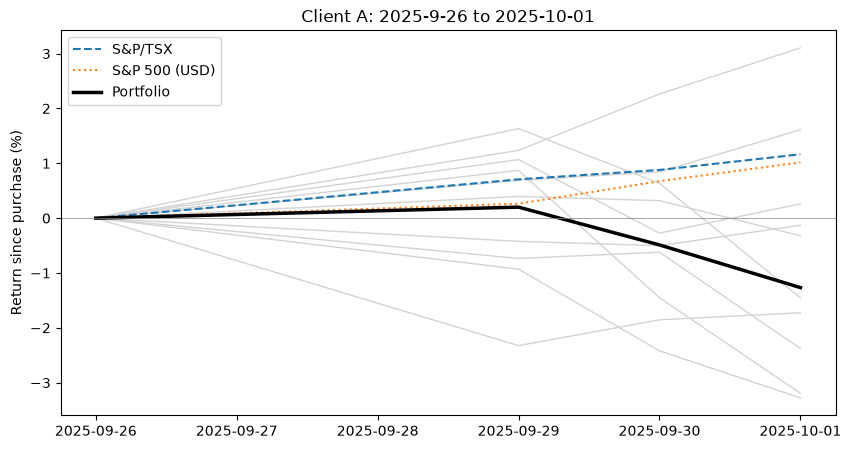

Return per stock (%):
Ticker
CAT      3.10
TD.TO    1.61
AMZN     0.26
AAPL    -0.13
UNP     -0.32
BLK     -1.45
QCOM    -1.73
TXN     -2.38
BB.TO   -3.19
USB     -3.28

Portfolio: -1.27%   S&P/TSX: 1.16%   S&P 500: 1.02%


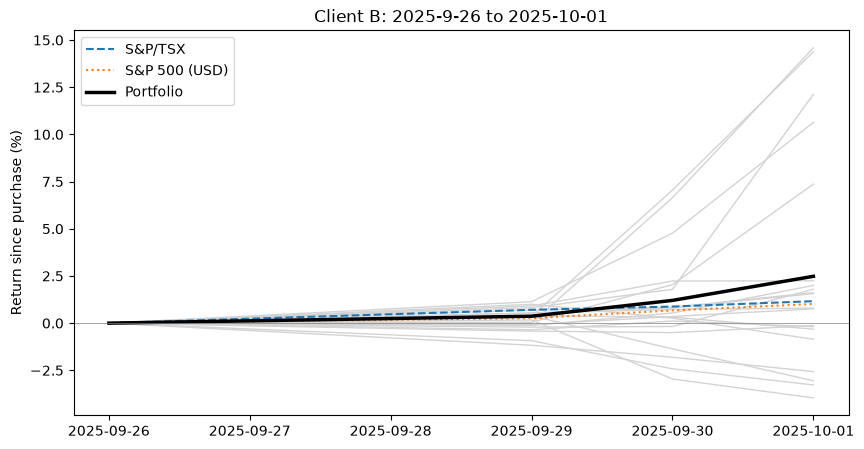

Return per stock (%):
Ticker
MRK      14.58
PFE      14.38
BIIB     12.13
ABBV     10.64
BMY       7.37
LMT       2.24
AIG       2.00
PEP       1.79
TD.TO     1.61
KO        1.56
RY.TO     0.80
MO        0.76
AAPL     -0.13
ABT      -0.19
UNP      -0.32
CL       -0.85
PM       -2.57
BAC      -3.05
USB      -3.28
AXP      -3.96

Portfolio: 2.48%   S&P/TSX: 1.16%   S&P 500: 1.02%


In [ ]:
import matplotlib.pyplot as plt

# Nov 27, 2025 was US Thanksgiving (US closed), so buy at the Nov 26 close, when both markets were open
TEST_BUY = "2025-9-26"
TEST_END = "2025-10-01"

def backtest_2025(weights, info, buy=TEST_BUY, end=TEST_END):
    """Buy-and-hold returns (CAD) of the given weights over a past window."""
    tickers = list(weights.index)
    end_plus_one = (pd.Timestamp(end) + pd.Timedelta(days=1)).strftime('%Y-%m-%d')  # end is exclusive

    close = yf.download(tickers + ['USDCAD=X', '^GSPTSE', '^GSPC'], start=buy, end=end_plus_one,
                        auto_adjust=False, progress=False)['Close'].ffill()

    #convert USD stocks to CAD, same as to_cad_prices
    prices = close[tickers].copy()
    for t in tickers:
        if info.loc[t, 'currency'] == 'USD':
            prices[t] = prices[t] * close['USDCAD=X']

    stock_returns = prices / prices.iloc[0] - 1  # each stock's return since the buy day
    portfolio = (stock_returns * weights).sum(axis=1)         # buy-and-hold: weights fixed at purchase
    bench = close[['^GSPTSE', '^GSPC']] / close[['^GSPTSE', '^GSPC']].iloc[0] - 1
    return stock_returns, portfolio, bench


def plot_backtest(weights, info, title):
    stock_returns, portfolio, bench = backtest_2025(weights, info)

    fig, ax = plt.subplots(figsize=(10, 5))
    for t in stock_returns.columns:                            # individual stocks in the background
        ax.plot(stock_returns.index, stock_returns[t] * 100, color='lightgray', linewidth=1)
    ax.plot(bench.index, bench['^GSPTSE'] * 100, '--', label='S&P/TSX')
    ax.plot(bench.index, bench['^GSPC'] * 100, ':', label='S&P 500 (USD)')
    ax.plot(portfolio.index, portfolio * 100, color='black', linewidth=2.5, label='Portfolio')

    ax.axhline(0, color='gray', linewidth=0.5)
    ax.set_ylabel('Return since purchase (%)')
    ax.set_title(title)
    ax.legend()
    plt.show()

    final = (stock_returns.iloc[-1] * 100).round(2).sort_values(ascending=False)
    print("Return per stock (%):")
    print(final.to_string())
    print(f"\nPortfolio: {portfolio.iloc[-1] * 100:.2f}%   "
          f"S&P/TSX: {bench['^GSPTSE'].iloc[-1] * 100:.2f}%   "
          f"S&P 500: {bench['^GSPC'].iloc[-1] * 100:.2f}%")


plot_backtest(weights_A, info, f"Client A: {TEST_BUY} to {TEST_END}")
plot_backtest(weights_B, info, f"Client B: {TEST_BUY} to {TEST_END}")

## Contribution and AI Declaration

**The following team members made a meaningful contribution to this assignment:**

Enter the names of all contributing members below (one name per line):

**To the best of our knowledge, no generative AI was used in preparing this submission.**

List only members who made a meaningful contribution. Contact the instructor before the deadline if someone should be omitted or if the team cannot make the declaration.